## TAIL RISK MODEL FOR 15 YEARS of NIFTY50 DATA USING EVT


### Historic Simulation

In [11]:
import pandas as pd
import numpy as np
df=pd.read_csv('Nifty 50 Historical Data.csv')

In [12]:
df["Price"] = df["Price"].astype(str).str.replace(r"[^\d.]", "", regex=True).astype(float)
# Calculating log return using consecutive closing prices
df["log_returns"] = np.log(df["Price"] / df["Price"].shift(1))

# Dropping the first row since it will be NaN (no previous day to compare to)
df = df.dropna(subset=["log_returns"])
df.head()

,Date,Price,Open,High,Low,Vol.,Change %,log_returns
1,06-10-2026,22776.10,"22,603.25","22,776.10","22,561.60",328.80M,0.98%,0.007627
2,05-10-2026,22555.75,"22,532.40","22,621.80","22,397.10",436.66M,0.60%,-0.009722
3,01-10-2026,22421.95,"22,543.70","22,610.60","22,217.30",463.55M,-0.88%,-0.005950
4,30-09-2026,22620.45,"22,665.00","22,809.35","22,595.20",378.96M,-0.42%,0.008814
5,29-09-2026,22716.20,"22,732.45","22,753.25","22,569.65",603.19M,-0.28%,0.004224


In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df["log_returns"], bins=50, color="steelblue", edgecolor="white")
ax.set(title="Frequency Distribution of NIFTY 50 Log Returns", xlabel="Log return", ylabel="Frequency")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

In [14]:
returns = df["log_returns"]
mu, sigma = returns.mean(), returns.std(ddof=1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(returns, bins=50, density=True, color="steelblue", edgecolor="white", alpha=0.7)
x = np.linspace(returns.min(), returns.max(), 500)
normal_curve = np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))
ax.plot(x, normal_curve, color="darkorange", linewidth=2, label=f"Normal fit (μ={mu:.4f}, σ={sigma:.4f})")

ax.set(title="NIFTY 50 Log Returns with Fitted Normal Curve",
    xlabel="Log return", ylabel="Density")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

In [15]:
from statistics import NormalDist

alpha = 0.001
z = NormalDist().inv_cdf(alpha)
phi = np.exp(-0.5 * z**2) / np.sqrt(2 * np.pi)

var_99 = -(mu + sigma * z)
cvar_99 = -(mu - sigma * phi / alpha)

print(f"99% VaR:  {var_99:.2%}")
print(f"99% CVaR: {cvar_99:.2%}")

99% VaR:  3.19%
99% CVaR: 3.48%


In [16]:
historical_cutoff = returns.quantile(alpha)
var_99_historical = -historical_cutoff
cvar_99_historical = -returns[returns <= historical_cutoff].mean()

print(f"Historical 99% VaR:  {var_99_historical:.2%}")
print(f"Historical 99% CVaR: {cvar_99_historical:.2%}")

Historical 99% VaR:  4.79%
Historical 99% CVaR: 6.42%


In [17]:
from scipy.stats import t

df_t, loc_t, scale_t = t.fit(returns)
q_t = t.ppf(alpha, df_t)

var_t = -(loc_t + scale_t * q_t)

# Expected shortfall for the lower tail of a Student's t distribution
cvar_t = -(
    loc_t
    - scale_t
    * ((df_t + q_t**2) / (df_t - 1))
    * t.pdf(q_t, df_t)
    / alpha
)

print(f"Fitted degrees of freedom: {df_t:.2f}")
print(f"Student's t VaR at {1 - alpha:.1%}:  {var_t:.2%}")
print(f"Student's t CVaR at {1 - alpha:.1%}: {cvar_t:.2%}")

Fitted degrees of freedom: 2.38
Student's t VaR at 99.9%:  9.59%
Student's t CVaR at 99.9%: 16.51%


In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import genpareto

class StandalonePOT:
    """
    Implements the Peaks Over Threshold (POT) method directly on raw returns 
    WITHOUT GARCH volatility filtering (Baseline Model).
    """
    def __init__(self, returns: pd.Series):
        self.returns = returns.dropna().values
        # Step 1: Invert signs so losses become positive numbers
        self.losses = -self.returns
        self.u = None
        self.exceedances = None
        self.xi = None
        self.beta = None

    def fit_gpd(self, u_quantile: float = 0.90):
        """
        Selects threshold u based on loss percentile and fits GPD via MLE.
        """
        # Step 2: Threshold is a positive number (e.g., 90th percentile of losses)
        self.u = np.quantile(self.losses, u_quantile)
        
        # Step 3: Extract positive exceedances where Loss > u
        self.exceedances = self.losses[self.losses > self.u] - self.u
        
        # Step 4: Fit GPD (floc=0 fixes location parameter to 0)
        self.xi, _, self.beta = genpareto.fit(self.exceedances, floc=0)
        return self

    def calculate_static_risk_metrics(self, alpha: float = 0.01):
        """
        Calculates STATIC VaR and CVaR at confidence level (1 - alpha).
        Note: These metrics do NOT update daily because there is no GARCH term.
        """
        if self.xi is None or self.beta is None:
            raise ValueError("Run fit_gpd() first.")

        n = len(self.losses)
        N_u = len(self.exceedances)

        # Static EVT VaR formula on raw returns
        var_static = self.u + (self.beta / self.xi) * (((n / N_u) * alpha)**(-self.xi) - 1)
        
        # Static EVT CVaR (Expected Shortfall) formula
        cvar_static = (var_static / (1 - self.xi)) + ((self.beta - self.xi * self.u) / (1 - self.xi))

        return {
            "threshold_u": self.u,
            "tail_index_xi": self.xi,
            "scale_beta": self.beta,
            f"Static_VaR_{int((1-alpha)*100)}%": var_static,
            f"Static_CVaR_{int((1-alpha)*100)}%": cvar_static
        }

# ==========================================
# Execution Example
# ==========================================
if __name__ == "__main__":
    np.random.seed(42)
    # Simulate 2,500 days of daily returns
    raw_returns = pd.Series(np.random.laplace(loc=0.0001, scale=0.012, size=2500))

    # Baseline Model: POT directly on raw returns
    baseline_pot = StandalonePOT(raw_returns)
    baseline_pot.fit_gpd(u_quantile=0.90)
    baseline_metrics = baseline_pot.calculate_static_risk_metrics(alpha=0.001)

    print("=== BASELINE MODEL: Standalone POT (No GARCH) ===")
    for key, val in baseline_metrics.items():
        print(f"{key:20s}: {val:.6f}")

=== BASELINE MODEL: Standalone POT (No GARCH) ===
threshold_u         : 0.019969
tail_index_xi       : -0.164289
scale_beta          : 0.012180
Static_VaR_99%      : 0.059316
Static_CVaR_99%     : 0.064226


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import genpareto

class StandalonePOT:
    """
    Implements the Peaks Over Threshold (POT) method directly on raw returns 
    WITHOUT GARCH volatility filtering (Baseline Model).
    """
    def __init__(self, returns: pd.Series):
        self.returns = returns.dropna().values
        # Step 1: Invert signs so losses become positive numbers
        self.losses = -self.returns
        self.u = None
        self.exceedances = None
        self.xi = None
        self.beta = None

    def fit_gpd(self, u_quantile: float = 0.90):
        """
        Selects threshold u based on loss percentile and fits GPD via MLE.
        """
        # Step 2: Threshold is a positive number (e.g., 90th percentile of losses)
        self.u = np.quantile(self.losses, u_quantile)
        
        # Step 3: Extract positive exceedances where Loss > u
        self.exceedances = self.losses[self.losses > self.u] - self.u
        
        # Step 4: Fit GPD (floc=0 fixes location parameter to 0)
        self.xi, _, self.beta = genpareto.fit(self.exceedances, floc=0)
        return self

    def calculate_static_risk_metrics(self, alpha: float = 0.01):
        """
        Calculates STATIC VaR and CVaR at confidence level (1 - alpha).
        Note: These metrics do NOT update daily because there is no GARCH term.
        """
        if self.xi is None or self.beta is None:
            raise ValueError("Run fit_gpd() first.")

        n = len(self.losses)
        N_u = len(self.exceedances)

        # Static EVT VaR formula on raw returns
        var_static = self.u + (self.beta / self.xi) * (((n / N_u) * alpha)**(-self.xi) - 1)
        
        # Static EVT CVaR (Expected Shortfall) formula
        cvar_static = (var_static / (1 - self.xi)) + ((self.beta - self.xi * self.u) / (1 - self.xi))

        return {
            "threshold_u": self.u,
            "tail_index_xi": self.xi,
            "scale_beta": self.beta,
            f"Static_VaR_{int((1-alpha)*100)}%": var_static,
            f"Static_CVaR_{int((1-alpha)*100)}%": cvar_static
        }

# ==========================================
# Execution Example
# ==========================================
if __name__ == "__main__":
    np.random.seed(42)
    # Simulate 2,500 days of daily returns
    raw_returns = pd.Series(np.random.laplace(loc=0.0001, scale=0.012, size=2500))

    # Baseline Model: POT directly on raw returns
    baseline_pot = StandalonePOT(raw_returns)
    baseline_pot.fit_gpd(u_quantile=0.90)
    baseline_metrics = baseline_pot.calculate_static_risk_metrics(alpha=0.001)

    print("=== BASELINE MODEL: Standalone POT (No GARCH) ===")
    for key, val in baseline_metrics.items():
        print(f"{key:20s}: {val:.6f}")

=== BASELINE MODEL: Standalone POT (No GARCH) ===
threshold_u         : 0.019969
tail_index_xi       : -0.164289
scale_beta          : 0.012180
Static_VaR_99%      : 0.059316
Static_CVaR_99%     : 0.064226


In [20]:
!pip install seaborn

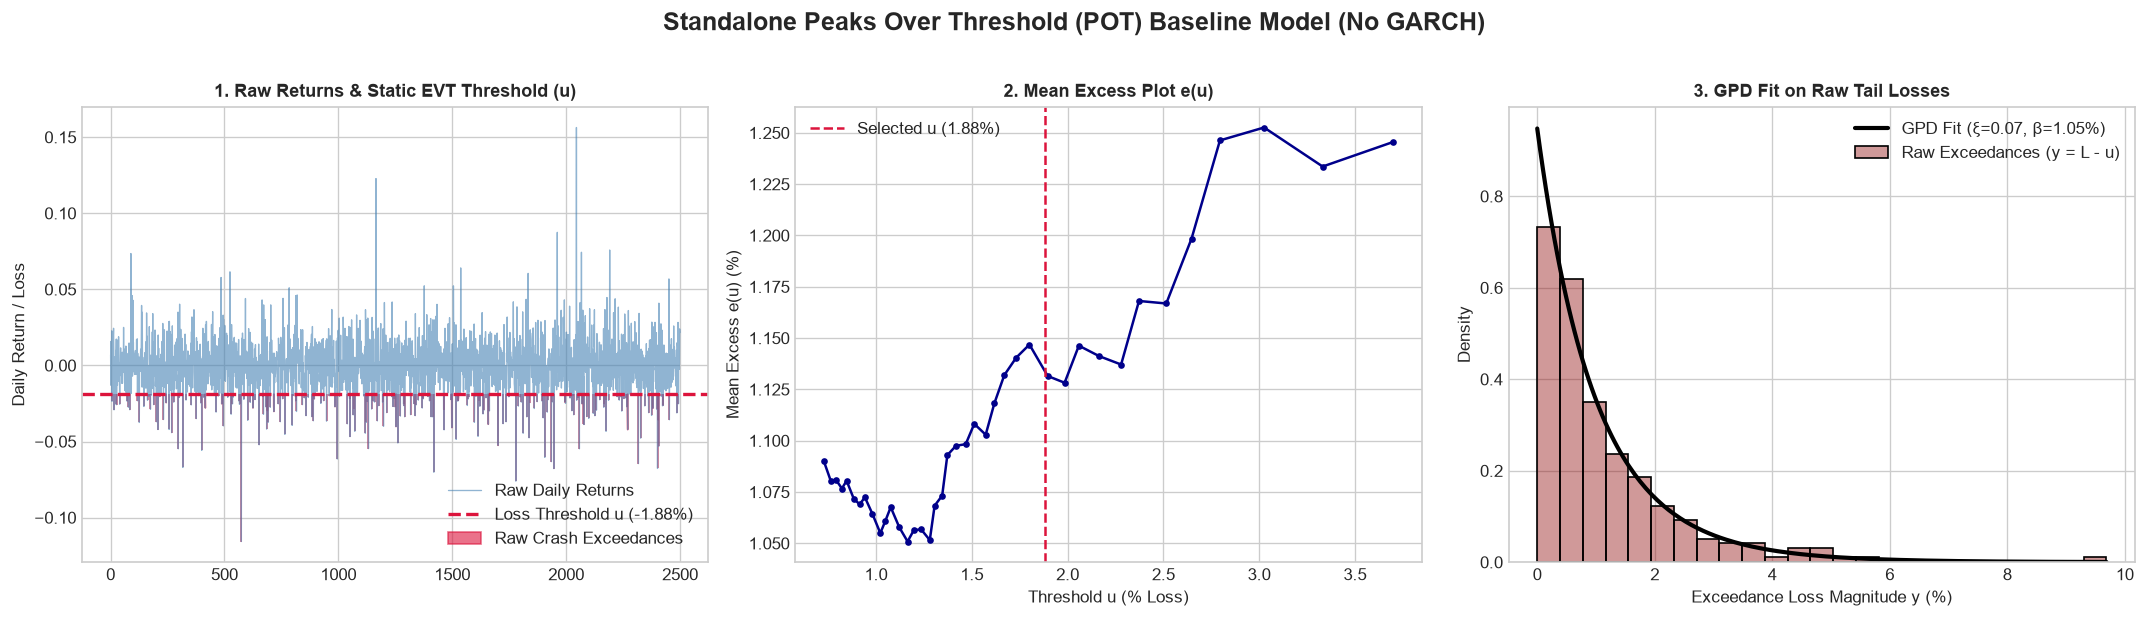

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import genpareto

# Set clean aesthetic style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=120)
fig.suptitle('Standalone Peaks Over Threshold (POT) Baseline Model (No GARCH)', fontsize=15, fontweight='bold', y=1.02)

# -----------------------------------------------------------------------------
# 1. Generate Raw Return Data with Heavy Tails
# -----------------------------------------------------------------------------
np.random.seed(42)
n_obs = 2500
# Simulate returns with fat-tailed Student-t distribution
raw_returns = pd.Series(np.random.standard_t(df=4, size=n_obs) * 0.012)
losses = -raw_returns.values  # Invert sign so crashes become positive loss values

# Select threshold u at 90th percentile of raw losses
u_quantile = 0.90
u = np.quantile(losses, u_quantile)
exceedances = losses[losses > u] - u

# Fit GPD directly to raw exceedances via Maximum Likelihood Estimation
xi, _, beta = genpareto.fit(exceedances, floc=0)

# -----------------------------------------------------------------------------
# Panel 1: Raw Returns Time Series & Static Loss Threshold
# -----------------------------------------------------------------------------
ax1 = axes[0]
ax1.plot(raw_returns, color='steelblue', alpha=0.6, linewidth=0.8, label='Raw Daily Returns')
ax1.axhline(-u, color='crimson', linestyle='--', linewidth=2, label=f'Loss Threshold u (-{u*100:.2f}%)')
ax1.fill_between(range(n_obs), raw_returns, -u, where=(raw_returns < -u), color='crimson', alpha=0.6, label='Raw Crash Exceedances')
ax1.set_title('1. Raw Returns & Static EVT Threshold (u)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Daily Return / Loss')
ax1.legend(loc='lower right')

# -----------------------------------------------------------------------------
# Panel 2: Diagnostic Mean Excess Plot (MEP) for Threshold Selection
# -----------------------------------------------------------------------------
threshold_grid = np.quantile(losses, np.linspace(0.70, 0.98, 40))
mean_excess_values = []

for u_val in threshold_grid:
    e_vals = losses[losses > u_val] - u_val
    mean_excess_values.append(np.mean(e_vals) if len(e_vals) > 0 else 0)

ax2 = axes[1]
ax2.plot(threshold_grid * 100, np.array(mean_excess_values) * 100, marker='o', color='darkblue', markersize=3, linestyle='-')
ax2.axvline(u * 100, color='crimson', linestyle='--', label=f'Selected u ({u*100:.2f}%)')
ax2.set_title('2. Mean Excess Plot e(u)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Threshold u (% Loss)')
ax2.set_ylabel('Mean Excess e(u) (%)')
ax2.legend(loc='upper left')

# -----------------------------------------------------------------------------
# Panel 3: GPD Tail Density Fit on Raw Loss Exceedances
# -----------------------------------------------------------------------------
ax3 = axes[2]
sns.histplot(exceedances * 100, stat='density', bins=25, color='darkred', alpha=0.4, ax=ax3, label='Raw Exceedances (y = L - u)')

# Plot GPD PDF
y_grid = np.linspace(0, max(exceedances), 200)
gpd_pdf = genpareto.pdf(y_grid, c=xi, scale=beta) / 100  # Scale for percentage plot
ax3.plot(y_grid * 100, gpd_pdf, color='black', linewidth=2.5, label=f'GPD Fit (ξ={xi:.2f}, β={beta*100:.2f}%)')

ax3.set_title('3. GPD Fit on Raw Tail Losses', fontsize=11, fontweight='bold')
ax3.set_xlabel('Exceedance Loss Magnitude y (%)')
ax3.set_ylabel('Density')
ax3.legend(loc='upper right')

plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.stats.diagnostic import het_arch

# Use the chronological percentage returns prepared in the GARCH cell
arch_lags = 10
mean_residuals = returns_pct.dropna() - returns_pct.dropna().mean()

lm_stat, lm_pvalue, f_stat, f_pvalue = het_arch(
    mean_residuals.to_numpy(),
    nlags=arch_lags
)

print(f"Engle ARCH LM test ({arch_lags} lags)")
print(f"LM statistic: {lm_stat:.3f}, p-value: {lm_pvalue:.6g}")
print(f"F statistic:  {f_stat:.3f}, p-value: {f_pvalue:.6g}")

if lm_pvalue < 0.05:
    print("Reject the null: evidence of ARCH effects supports modeling time-varying volatility with GARCH.")
else:
    print("Do not reject the null: this test provides insufficient evidence of ARCH effects.")

In [23]:
from arch import arch_model
from scipy.stats import genpareto

# Rebuild returns in chronological order before fitting GARCH
garch_data = df.copy()
garch_data["Date"] = pd.to_datetime(garch_data["Date"], dayfirst=True)
garch_data["Price"] = pd.to_numeric(garch_data["Price"], errors="coerce")
garch_data = garch_data.dropna(subset=["Date", "Price"]).sort_values("Date")
returns_pct = (100 * np.log(garch_data["Price"] / garch_data["Price"].shift(1))).dropna()

# Fit GARCH(1,1) with Student-t innovations
garch_fit = arch_model(
    returns_pct, mean="Constant", vol="GARCH", p=1, q=1, dist="t", rescale=False
).fit(disp="off")

# Fit a GPD to the upper tail of standardized losses
standardized_residuals = (
    garch_fit.resid / garch_fit.conditional_volatility
).dropna()
standardized_losses = -standardized_residuals.to_numpy()

threshold = np.quantile(standardized_losses, 0.90)
exceedances_gpd = standardized_losses[standardized_losses > threshold] - threshold
xi_gpd, _, beta_gpd = genpareto.fit(exceedances_gpd, floc=0)

# EVT quantile and expected shortfall for standardized losses
tail_probability = len(exceedances_gpd) / len(standardized_losses)

if alpha >= tail_probability:
    raise ValueError("alpha must be smaller than the probability of exceeding the GPD threshold.")

if abs(xi_gpd) < 1e-8:
    evt_var_z = threshold + beta_gpd * np.log(tail_probability / alpha)
else:
    evt_var_z = threshold + (beta_gpd / xi_gpd) * (
        (tail_probability / alpha) ** xi_gpd - 1
    )

evt_es_z = (
    (evt_var_z + beta_gpd - xi_gpd * threshold) / (1 - xi_gpd)
    if xi_gpd < 1
    else np.inf
)

# One-step-ahead GARCH volatility and mean, in percentage-return units
forecast = garch_fit.forecast(horizon=1, reindex=False)
next_mean_pct = forecast.mean.iloc[-1, 0]
next_vol_pct = np.sqrt(forecast.variance.iloc[-1, 0])

# Convert the standardized EVT tail estimates into return-loss risk
var_pct = next_vol_pct * evt_var_z - next_mean_pct
es_pct = next_vol_pct * evt_es_z - next_mean_pct

print(f"GARCH next-day volatility: {next_vol_pct:.3f}%")
print(f"GPD shape (xi): {xi_gpd:.4f}")
print(f"GPD scale (beta): {beta_gpd:.4f}")
print(f"EVT VaR at {1 - alpha:.1%}: {var_pct:.3f}%")
print(f"EVT expected shortfall at {1 - alpha:.1%}: {es_pct:.3f}%")

GARCH next-day volatility: 0.825%
GPD shape (xi): 0.0347
GPD scale (beta): 0.6278
EVT VaR at 99.9%: 3.570%
EVT expected shortfall at 99.9%: 4.200%


In [ ]:
tail_losses = standardized_losses[standardized_losses > threshold]
x_grid = np.linspace(threshold, tail_losses.max(), 400)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(
    tail_losses,
    bins=25,
    density=True,
    alpha=0.55,
    color="steelblue",
    edgecolor="white",
    label="Standardized losses above threshold",
)
ax.plot(
    x_grid,
    genpareto.pdf(x_grid - threshold, c=xi_gpd, loc=0, scale=beta_gpd),
    color="darkred",
    linewidth=2,
    label=f"GPD fit (ξ={xi_gpd:.3f}, β={beta_gpd:.3f})",
)
ax.axvline(threshold, color="black", linestyle="--", label=f"Threshold = {threshold:.3f}")
ax.set(
    title="GPD Fit to Standardized Residual Loss Tail",
    xlabel="Standardized loss",
    ylabel="Conditional density",
)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()